# LEAF-1 embedding plus genomic bins on the Zhang 2021 atlas

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Does adding coordinate-level features to the LEAF-1 embedding help cell-type
classification? Each of the 102 one-vs-all tasks is scored with the embedding
alone and with an early fusion of the embedding and genomic-bin counts (log1p on
the bins, top-K bins by variance in inner CV, the embedding always kept), at
four bin resolutions, on the atlas's predefined folds. Each point is one cell
type, AUC averaged over the five folds; above y = x the fusion helps.

Colour marks the cell types where the bins alone beat the embedding. Rows of
the source table are indexed by the number of genome-wide bins; panels are
labelled by bin size (10,000 bins = 300 kb ... 300,000 bins = 10 kb).

Layout, sizes and styling follow the published Supplementary Figure 4
(leaf-1-figures `supp_scatac_embedding_vs_binning_resolution.ipynb`), which
plots the same embedding AUCs against the bins alone.

Panel:
- `scatac_hybrid_emb_bin_auc`: a-d, 300 / 100 / 30 / 10 kb bins.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: scatac/data
OUT : scatac/output


In [2]:
# ── Constants and data ────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Supplementary Figure 4's rcParams, with leaf-1-figures' shared font order.
SUPP4_RC = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica", "Liberation Sans"],
    "font.size": 6, "axes.titlesize": 7, "axes.labelsize": 6,
    "xtick.labelsize": 5, "ytick.labelsize": 5, "legend.fontsize": 5,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
}
BIN_LABEL = {10000: "300 kb", 30000: "100 kb", 100000: "30 kb", 300000: "10 kb"}
# Embedding-wins in Supp. Fig. 4's blue; bins-win in Okabe-Ito vermillion.
C_EMB, C_BIN = OKABE_ITO["blue"], OKABE_ITO["vermillion"]

df = pd.read_csv(DATA / "scatac_hybrid_emb_bin_per_task.csv", float_precision="round_trip")
summ = pd.read_csv(DATA / "scatac_hybrid_emb_bin_summary.csv", float_precision="round_trip")
assert df.groupby("n_bins").size().eq(102).all()
print(df.groupby("n_bins")[["emb_auc", "bin_auc", "hybrid_auc"]].mean().round(4).to_string())

        emb_auc  bin_auc  hybrid_auc
n_bins                              
10000    0.9355   0.9225      0.9549
30000    0.9355   0.8887      0.9450
100000   0.9355   0.8132      0.9312
300000   0.9355   0.7290      0.9278


saved: scatac/output/scatac_hybrid_emb_bin_auc.pdf
saved: scatac/output/scatac_hybrid_emb_bin_auc.png
saved: scatac/output/scatac_hybrid_emb_bin_auc.svg
saved: scatac/output/scatac_hybrid_emb_bin_auc.tsv


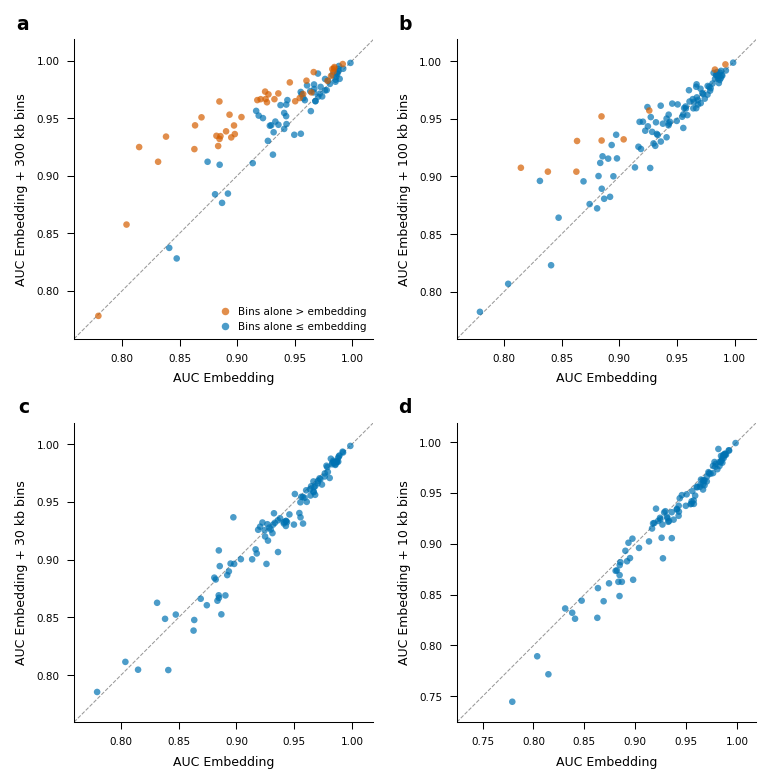

In [3]:
# ── Figure ─────────────────────────────────────────────────────────────────────
with plt.rc_context(SUPP4_RC):
    fig, axes = plt.subplots(2, 2, figsize=(5.2, 5.2))
    for ax, (nb, lab), letter in zip(axes.ravel(), BIN_LABEL.items(), "abcd"):
        d = df[df.n_bins == nb]
        x, y = d.emb_auc.to_numpy(), d.hybrid_auc.to_numpy()
        lo = min(x.min(), y.min()) - 0.02           # per-panel square limits, as Supp. Fig. 4
        hi = max(x.max(), y.max()) + 0.02
        ax.plot([lo, hi], [lo, hi], ls="--", color="0.6", lw=0.5, zorder=1)
        for flag, color in ((False, C_EMB), (True, C_BIN)):
            m = (d.bin_beats_emb == flag).to_numpy()
            ax.scatter(x[m], y[m], c=color, s=10, alpha=0.7, edgecolors="none",
                       zorder=3, rasterized=True)
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
        ax.set_xlabel("AUC Embedding", fontsize=6)
        ax.set_ylabel(f"AUC Embedding + {lab} bins", fontsize=6)
        ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
        ax.text(-0.15, 1.02, letter, transform=ax.transAxes, fontsize=9,
                fontweight="bold", va="bottom", ha="right")
    mk = dict(marker="o", linestyle="", markersize=3.6, markeredgewidth=0, alpha=0.7)
    axes[0, 0].legend(handles=[Line2D([], [], color=C_BIN, label="Bins alone > embedding", **mk),
                               Line2D([], [], color=C_EMB, label="Bins alone \u2264 embedding", **mk)],
                      loc="lower right", frameon=False, handletextpad=0.2, borderaxespad=0.3)
    plt.tight_layout()
    src = df.assign(bin_size=df.n_bins.map(BIN_LABEL))
    savefig(fig, OUT, "scatac_hybrid_emb_bin_auc", data=src)
    plt.show()

In [4]:
# ── Numbers for the figure legend ─────────────────────────────────────────────
# From the source summary: Wilcoxon signed-rank on the per-task fusion gain.
for nb, lab in BIN_LABEL.items():
    a = summ[(summ.n_bins == nb) & (summ.subset == "all")].iloc[0]
    n_bin_wins = int(df[(df.n_bins == nb)].bin_beats_emb.sum())
    print(f"{lab:>6}: embedding {a.emb_auc:.3f}, bins {a.bin_auc:.3f}, fusion {a.hybrid_auc:.3f}; "
          f"mean gain {a.mean_delta_hybrid_emb:+.4f}, fusion higher in {a.frac_targets_improved:.0%} "
          f"of {int(a.n_targets)} types, Wilcoxon P = {a.wilcoxon_p:.1e}; bins beat embedding in {n_bin_wins}")

300 kb: embedding 0.935, bins 0.922, fusion 0.955; mean gain +0.0194, fusion higher in 76% of 102 types, Wilcoxon P = 9.4e-12; bins beat embedding in 41
100 kb: embedding 0.935, bins 0.889, fusion 0.945; mean gain +0.0096, fusion higher in 65% of 102 types, Wilcoxon P = 1.3e-05; bins beat embedding in 10
 30 kb: embedding 0.935, bins 0.813, fusion 0.931; mean gain -0.0042, fusion higher in 27% of 102 types, Wilcoxon P = 6.2e-06; bins beat embedding in 0
 10 kb: embedding 0.935, bins 0.729, fusion 0.928; mean gain -0.0076, fusion higher in 20% of 102 types, Wilcoxon P = 6.1e-12; bins beat embedding in 0
